In [1]:
import os
import json
import torch
import numpy as np
import matplotlib.pyplot as plt

from dataset.singlecell import SingleCellDataset
from models.vae import VAE

# 256 Full
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/256/2024-07-26/19-37-24"

# 512 Full
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/512/2024-07-26/19-36-52"

# 1024 High level
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/1024/2024-09-22/23-52-16" # Top 6500
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/1024/2024-09-23/00-21-18" # Top 15000
exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/1024/2024-09-23/00-23-05" # All
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/1024/2024-09-23/01-36-42" # Top 1000
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/1024/2024-09-23/01-41-13" # Top 100
# 1024 High level dropout
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/1024/2024-09-03/20-38-54"
# 1024 min2K
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/1024/2024-07-03/13-58-28"
# 1024 Full
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/1024/2024-07-26/18-38-05"

# 2048 min2K
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/2048/2024-07-23/16-15-30"
# 2048 Full
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/2048/2024-07-23/16-10-06"

# 4096 min2K
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/4096/2024-07-23/17-26-46"
# 4096 Full
# exp_dir = "/home/lagandua/projects/sven/pineapple/exp/vae/4096/2024-07-23/16-12-03"

project_dir = "/home/lagandua/projects/sven/pineapple"
model_path = f"{exp_dir}/model_49.pth"
label_to_idx_path = f"{exp_dir}/label_to_index.json"
data_name = "val_high_all_genes_10"
data_path = f"{project_dir}/data/sven_classes/{data_name}.npz"
# data_path = f"{project_dir}/data/Predicted_labels_CellTypist/{data_name}.npz"
out_dir = f"{project_dir}/exp/plots/vae-kmeans/"
os.makedirs(out_dir, exist_ok=True)
comment = "kldiv-w-25e-5"
device = 'cuda:0'
latent_dim = int(exp_dir.split("/")[-3])

In [2]:
label_to_index = json.load(open(label_to_idx_path))

In [3]:
val_dataset = SingleCellDataset(data_path)
val_dataset.label_to_index = label_to_index
val_dataset.label_indices = [val_dataset.label_to_index[label] for label in val_dataset.labels]
val_dataloader = torch.utils.data.DataLoader(
        val_dataset, batch_size=256, shuffle=False
    )

In [4]:
input_size = val_dataset.data.shape[-1]
num_classes = len(val_dataset.label_to_index)
latent_dim = latent_dim
model = (
        VAE(input_size, latent_dim=latent_dim)
        .to(device)
        .float()
    )
model.load_state_dict(torch.load(model_path))
model.eval()

VAE(
  (activation): ELU(alpha=1.0)
  (encoder): Sequential(
    (0): Sequential(
      (0): Linear(in_features=32689, out_features=4096, bias=True)
      (1): BatchNorm1d(4096, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): Dropout(p=0.2, inplace=False)
      (3): ELU(alpha=1.0)
    )
    (1): Sequential(
      (0): Linear(in_features=4096, out_features=2048, bias=True)
      (1): BatchNorm1d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): Dropout(p=0.2, inplace=False)
      (3): ELU(alpha=1.0)
    )
    (2): Sequential(
      (0): Linear(in_features=2048, out_features=1024, bias=True)
      (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): Dropout(p=0.2, inplace=False)
      (3): ELU(alpha=1.0)
    )
  )
  (fc_mu): Linear(in_features=1024, out_features=1024, bias=True)
  (fc_logvar): Linear(in_features=1024, out_features=1024, bias=True)
  (decoder): Sequential(
    (0): Seque

In [5]:
val_reps = []
val_recons = []
val_inputs = []
val_labels = []
with torch.no_grad():
    for val_input, val_target in val_dataloader:
        val_input = val_input.to(device).float()
        recon, z, _ = model(val_input)

        val_labels.extend(val_target.cpu().numpy().tolist())
        val_reps.extend(z.cpu().numpy().tolist())
        val_recons.extend(recon.cpu().numpy().tolist())
        val_inputs.extend(val_input.cpu().numpy().tolist())

In [6]:
index_to_label = {v: k for k, v in val_dataset.label_to_index.items()} # Useful for plot legend


In [7]:
# json.dump(index_to_label, open("index_to_label.json", "w"))

In [8]:
import numpy as np
import matplotlib.pyplot as plt

val_reps = np.array(val_reps)
count = len(val_reps)

# Embeddings
embeddings = np.copy(val_reps[:count])

# Labels
# labels = np.copy(val_dataset.label_indices[:count])
labels = np.array(val_labels)

In [9]:
# import umap

# # Initialize UMAP model
# umap_model = umap.UMAP(n_neighbors=15, n_components=2, metric='euclidean')

# # Fit and transform the embeddings
# umap_embeddings = umap_model.fit_transform(embeddings)

In [10]:
# cmap = plt.get_cmap('gist_rainbow')
# values = np.linspace(0, 1, len(set(labels)))
# colours = [cmap(val) for val in values]

# # Plot the UMAP results
# plt.figure(figsize=(8, 6))
# handles = [plt.scatter(umap_embeddings[labels == l, 0], umap_embeddings[labels == l, 1], s=1, c=colours[l]) for l in set(labels)]
# custom_labels = [index_to_label[lbl] for lbl in set(labels)]  # Map to custom label names

# # Create a legend with custom labels
# plt.legend(handles, custom_labels, title="Classes", loc="upper right", bbox_to_anchor=(1.45, 1.0))

# plt.xlabel('UMAP 1')
# plt.ylabel('UMAP 2')
# plt.tight_layout()
# plt.savefig(f"{out_dir}/umap-vae-{latent_dim}-{data_name}-{comment}.png")
# plt.show()

In [11]:
from sklearn.manifold import TSNE

# Perform t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(embeddings)


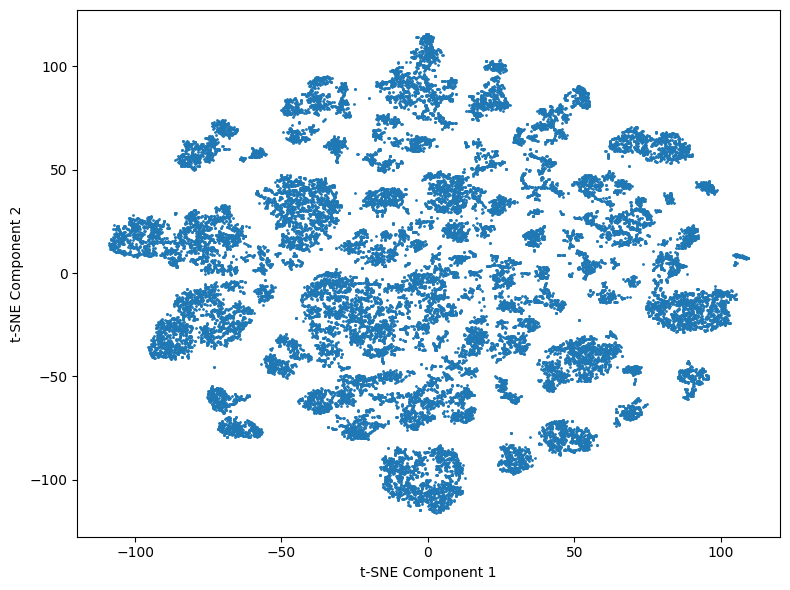

In [12]:
cmap = plt.get_cmap('tab20')
values = np.linspace(0, 1, len(set(labels)))
colours = [cmap(val) for val in values]

# Plot the UMAP results
plt.figure(figsize=(8, 6))
# handles = [plt.scatter(X_embedded[labels == l, 0], X_embedded[labels == l, 1], s=1, c=colours[l]) for l in set(labels)]
plt.scatter(X_embedded[:, 0], X_embedded[:, 1], s=1)
custom_labels = [index_to_label[lbl] for lbl in set(labels)]

# Create a legend with custom labels
# plt.legend(handles, custom_labels, title="Classes", loc="upper right", bbox_to_anchor=(1.45, 1))

# Show label mappings in the title
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.tight_layout()
# plt.savefig(f"{out_dir}/t-SNE-{latent_dim}-{data_name}-{comment}-no-classes.png")
plt.show()

/tmp/ipykernel_1846352/2452269374.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  handles = [plt.scatter(X_embedded[labels == l, 0], X_embedded[labels == l, 1], s=1, c=colours[l]) for l in set(labels)]


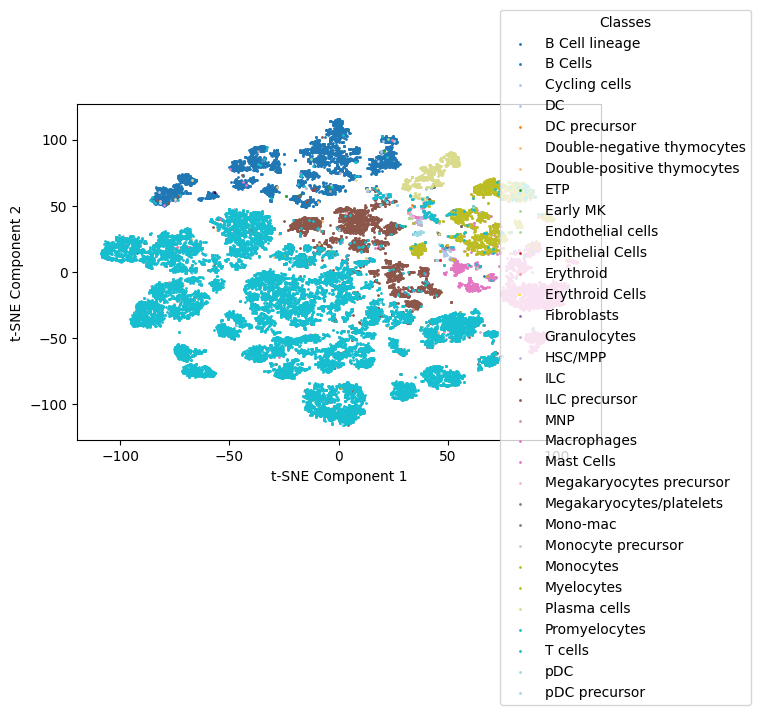

In [13]:
cmap = plt.get_cmap('tab20')
values = np.linspace(0, 1, len(set(labels)))
colours = [cmap(val) for val in values]

# Plot the UMAP results
plt.figure(figsize=(8, 6))
handles = [plt.scatter(X_embedded[labels == l, 0], X_embedded[labels == l, 1], s=1, c=colours[l]) for l in set(labels)]
custom_labels = [index_to_label[lbl] for lbl in set(labels)]

# Create a legend with custom labels
plt.legend(handles, custom_labels, title="Classes", loc="upper right", bbox_to_anchor=(1.3, 1.3))

# Show label mappings in the title
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.tight_layout()
# plt.savefig(f"{out_dir}/t-SNE-{latent_dim}-{data_name}-{comment}-true-classes.png")
plt.show()

In [14]:
# Perform KMeans clustering with sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import time
# Initialize KMeans model
kmeans = KMeans(n_clusters=num_classes*1, random_state=42)

start_time = time.time()
# Fit and predict the embeddings
kmeans_results = kmeans.fit_predict(embeddings)

print(f"KMeans took {time.time() - start_time} seconds")

KMeans took 2.6288886070251465 seconds


/tmp/ipykernel_1846352/2522102365.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  handles = [plt.scatter(X_embedded[kmeans_results == l, 0], X_embedded[kmeans_results == l, 1], s=1, c=km_colours[l]) for l in set(kmeans_results)]


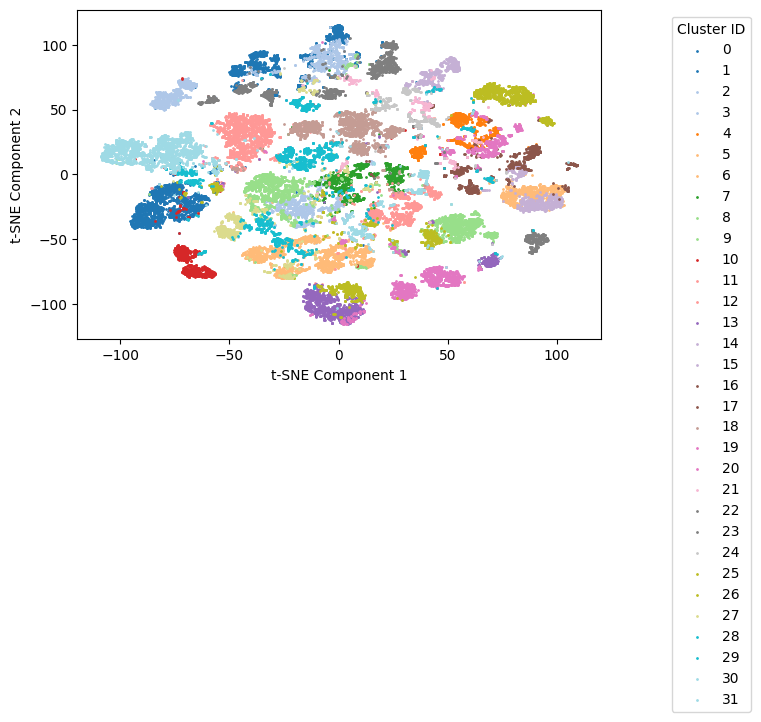

In [15]:
cmap = plt.get_cmap('tab20')
km_values = np.linspace(0, 1, len(set(kmeans_results)))
km_colours = [cmap(val) for val in km_values]

# Plot the UMAP results
plt.figure(figsize=(8, 6))
handles = [plt.scatter(X_embedded[kmeans_results == l, 0], X_embedded[kmeans_results == l, 1], s=1, c=km_colours[l]) for l in set(kmeans_results)]
custom_labels = [lbl for lbl in set(kmeans_results)]

# Create a legend with custom labels
plt.legend(handles, custom_labels, title="Cluster ID", loc="upper right", bbox_to_anchor=(1.3, 1))

# Show label mappings in the title
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.tight_layout()
# plt.savefig(f"{out_dir}/t-SNE-{latent_dim}-{data_name}-{comment}-pred-clusters.png")
plt.show()

In [16]:
# np.savez("cluster-assignments.npz", cluster_id=kmeans_results, labels=labels, embeddings=embeddings, tsne=X_embedded)

In [17]:
class_to_cluster = {}
cluster_to_class = {}
exemplar_count = 5
exemplar_count_temp = exemplar_count
label_counter = 0
for c_id in range(len(set(kmeans_results))):
    cluster_indices = np.where(kmeans_results == c_id)[0]
    if len(cluster_indices) < exemplar_count:
        exemplar_count_temp = len(cluster_indices)
    else:
        exemplar_count_temp = exemplar_count
    exemplar_indices = np.random.choice(cluster_indices, exemplar_count_temp, replace=False)
    exemplar_reps = embeddings[exemplar_indices]
    exemplar_labels = labels[exemplar_indices]
    exemplar_class = np.argmax(np.bincount(exemplar_labels))
    class_to_cluster[exemplar_class] = c_id
    cluster_to_class[c_id] = exemplar_class
    label_counter += exemplar_count_temp
kmeans_results_new = np.array([cluster_to_class[c_id] for c_id in kmeans_results])
print(f"Total exemplars labeled: {label_counter}")

Total exemplars labeled: 160


/tmp/ipykernel_1846352/3831955785.py:5: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  handles = [plt.scatter(X_embedded[kmeans_results_new == l, 0], X_embedded[kmeans_results_new == l, 1], s=1, c=colours[l]) for l in set(kmeans_results_new)]


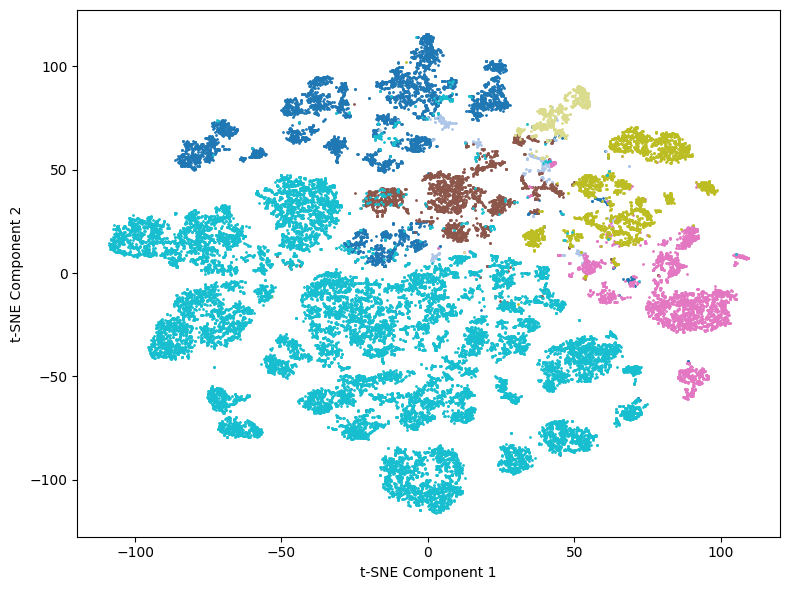

In [18]:
cmap = plt.get_cmap('tab10')

# Plot the UMAP results
plt.figure(figsize=(8, 6))
handles = [plt.scatter(X_embedded[kmeans_results_new == l, 0], X_embedded[kmeans_results_new == l, 1], s=1, c=colours[l]) for l in set(kmeans_results_new)]
custom_labels = [index_to_label[lbl] for lbl in set(kmeans_results_new)]

# Create a legend with custom labels
# plt.legend(handles, custom_labels, title="Classes (from Clusters)", loc="upper right", bbox_to_anchor=(1.45, 1))

# Show label mappings in the title
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.tight_layout()
# plt.savefig(f"{out_dir}/t-SNE-{latent_dim}-{data_name}-{comment}-cluster-labeled.png")
plt.show()

In [19]:
# Perform k-NN based classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Initialize KNN model
knn = KNeighborsClassifier(n_neighbors=30)

start_time = time.time()
# Fit the KNN model
knn.fit(embeddings, kmeans_results_new)
print(f"KNN took {time.time() - start_time} seconds")

# Predict the clusters
knn_results = knn.predict(embeddings)

# Calculate the accuracy
accuracy = accuracy_score(labels, knn_results)
print("k-NN Classifier Accuracy:", accuracy)

KNN took 0.034034013748168945 seconds


k-NN Classifier Accuracy: 0.8497998544395924


In [20]:
# F1 Score
from sklearn.metrics import f1_score
f1 = f1_score(labels, knn_results, average='weighted')
print("k-NN Classifier F1 Score:", f1)

k-NN Classifier F1 Score: 0.8290867367973295
